# Age structure per municipality: young and older residents

This notebook maps the share of young residents (0 to 25 years) and older residents (65 years and over) in all Dutch municipalities.

**Required files:**
- `data/processed/age_per_municipality.csv`: share of residents aged 0 to 25 and aged 65 and over per municipality (% of total population), made by notebook 0.1
- `data/raw/gemeenten_2024.gpkg`: municipal boundaries from CBS/PDOK, 2024 municipal division
- `data/processed/chargingpoints_households_income.csv`: made by notebook 1, only used to check that the names match

**Output:**
- `figures/map_age_per_municipality.png`

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

## 1. Load the data

Notebook 0.1 has already combined the two CBS age files into one table.

In [2]:
age = pd.read_csv("../data/processed/age_per_municipality.csv")

print("Number of municipalities:", len(age))
display(age.head())

Number of municipalities: 342


,municipality,pct_young_0_25,pct_older_65plus
0,Aa en Hunze,22.8,29.8
1,Aalsmeer,28.3,19.6
2,Aalten,25.8,25.1
3,Achtkarspelen,28.4,22.8
4,Alblasserdam,30.3,20.9


## 2. Harmonise municipality names

The CBS age files write some names differently from the charging point file, for example *'s-Gravenhage (gemeente)* instead of *Den Haag*. We use the spelling of the charging point file everywhere. If a name is already written that way, `replace` leaves it unchanged.

In [3]:
name_mapping = {
    "'s-Gravenhage (gemeente)": "Den Haag",
    "Groningen (gemeente)": "Groningen",
    "Utrecht (gemeente)": "Utrecht",
    "Beek (L.)": "Beek",
    "Stein (L.)": "Stein",
    "Hengelo (O.)": "Hengelo",
    "Laren (NH.)": "Laren",
    "Middelburg (Z.)": "Middelburg",
    "Rijswijk (ZH.)": "Rijswijk",
}
age["municipality"] = age["municipality"].str.strip().replace(name_mapping)

# Check: does every municipality match the charging point data? Both lines should print set()
charging = pd.read_csv("../data/processed/chargingpoints_households_income.csv")
print("Only in the age data:", set(age["municipality"]) - set(charging["municipality"]))
print("Only in the charging data:", set(charging["municipality"]) - set(age["municipality"]))

Only in the age data: set()
Only in the charging data: set()


## 3. Join the data to the map

The boundary file uses CBS names as well. We convert these to the same spelling, so the map can be joined on the municipality name.

In [4]:
municipalities = gpd.read_file("../data/raw/gemeenten_2024.gpkg", layer="gemeente_gegeneraliseerd")

# Names in the boundary file (left) -> spelling of the charging point file (right)
map_name_mapping = {
    "'s-Gravenhage": "Den Haag",
    "Beek (L.)": "Beek",
    "Hengelo (O.)": "Hengelo",
    "Laren (NH.)": "Laren",
    "Middelburg (Z.)": "Middelburg",
    "Rijswijk (ZH.)": "Rijswijk",
    "Stein (L.)": "Stein",
}
municipalities["municipality"] = municipalities["statnaam"].replace(map_name_mapping)

age_gdf = municipalities.merge(age, on="municipality", how="left")

# Check: should print 0
print("Municipalities without data:", age_gdf["pct_young_0_25"].isna().sum())

Municipalities without data: 0


## 4. Create the maps

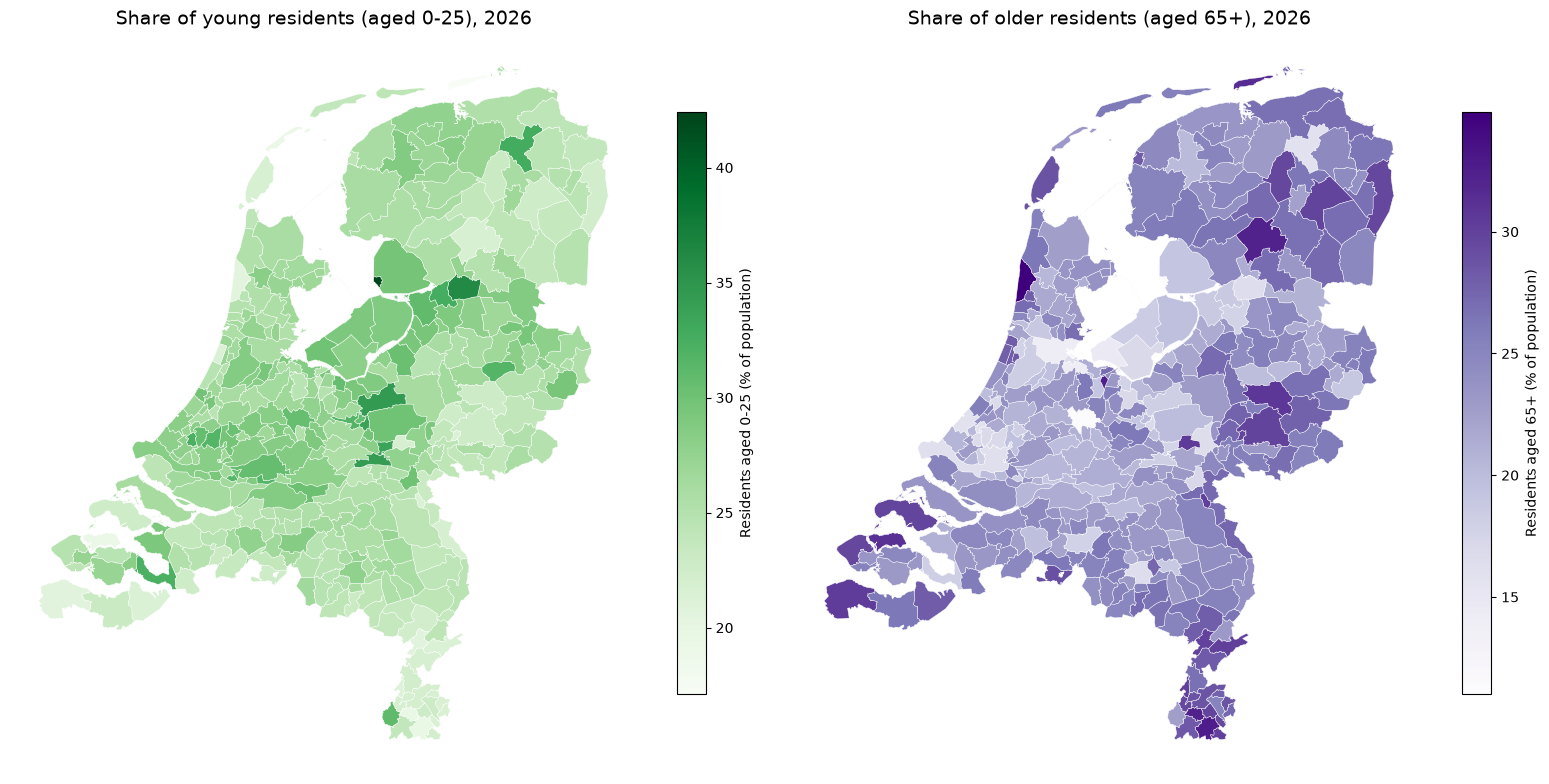

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 10))

age_gdf.plot(
    column="pct_young_0_25",
    cmap="Greens",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={"label": "Residents aged 0-25 (% of population)", "shrink": 0.6},
    ax=axes[0],
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
axes[0].set_title("Share of young residents (aged 0-25), 2026", fontsize=14)
axes[0].axis("off")

age_gdf.plot(
    column="pct_older_65plus",
    cmap="Purples",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={"label": "Residents aged 65+ (% of population)", "shrink": 0.6},
    ax=axes[1],
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
axes[1].set_title("Share of older residents (aged 65+), 2026", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/map_age_per_municipality.png", dpi=200)
plt.show()